# main

Tech stack

Foundational
- [HTMX](https://htmx.org/)
- [HTML](https://developer.mozilla.org/en-US/docs/Web/HTML/Reference/Elements)
- [CSS](https://developer.mozilla.org/en-US/docs/Web/CSS)

Abstractions
- [FastHTML](https://fastht.ml/docs/) 
- [MonsterUI](https://monsterui.answer.ai)
- [Tailwind](https://tailwindcss.com/docs)
- [FastLite](https://fastlite.answer.ai/)
- [Starlette](https://starlette.dev/)
- [Uvicorn](https://uvicorn.dev/)

In [ ]:
import os,random,secrets
from datetime import date
from fasthtml.common import *
from fastlite import *
from monsterui.all import *

In [ ]:
def set_scope_before(req, sess):
    req.scope.setdefault('auth', sess.get('auth'))

def user_auth_before(req, sess):
    auth = req.scope.get('auth')
    if auth: return
    sess['next'] = req.url.path
    return Redirect('/login')
    
def mk_nav(auth=None):
    authed = [A(href='/tests/new')(H4('Test')), A(href='/tests')(H4('Data')), A(href='/logout')(H4('Logout'))]
    anon = [A(href='/login')(H4('Login'))]
    return NavBar(
        *(authed if auth else anon),
        brand=A(href='/')(H2('COBALT')),
        cls='bg-primary text-primary-content py-4 px-16')

def mk_shell(c, req):
    auth = req.scope.get('auth', None)
    return mk_nav(auth), Main(id='main')(c)

before = [
    Beforeware(set_scope_before),
    Beforeware(user_auth_before, skip=[r'/favicon\.ico', '/login', '/logout', '/'])]
    
app,rt = fast_app(
    title='COBALT',
    before=before,
    session_cookie='session_cobalt',
    secret_key=secrets.token_hex(32),
    hdrs=Theme.blue.headers(katex=True, apex_charts=True),
    body_wrap=mk_shell)

## Index

In [ ]:
@rt
def index(): return Container(render_md(Path('README.md').read_text()))

## Development helpers

In [ ]:
from fasthtml.jupyter import HTMX,JupyUvi

if 'srv' not in globals(): srv = JupyUvi(app)
p = partial(HTMX, app=app, host=None, port=None, height=500)

This is useful to preview how components look.

In [ ]:
c = Div(cls='flex justify-center pt-4')(
    Card(
        H3('Researcher Login'),
        P(id='errormsg', cls=TextT.error+TextT.bold),
        Form(hx_post='/login', hx_target='#errormsg')(
            LabelInput('Username', id='username', name='username', autocomplete='username'),
            LabelInput('Password', id='password', name='password', type='password', autocomplete='current-password'),
            Button(cls=ButtonT.primary)('Log in')),
        cls='w-96'))
p(c)

HTML(<iframe srcdoc="404 Not Found" style="width: 100%; height: 500px; border: none;" onload="" allow="accelerometer; autoplay; camera; clipboard-read; clipboard-write; display-capture; encrypted-media; fullscreen; gamepad; geolocation; gyroscope; hid; identity-credentials-get; idle-detection; magnetometer; microphone; midi; payment; picture-in-picture; publickey-credentials-get; screen-wake-lock; serial; usb; web-share; xr-spatial-tracking"></iframe> )

## Auth

In [ ]:
RESEARCHER_USER,RESEARCHER_PASS = os.getenv('RESEARCHER_USER'),os.getenv('RESEARCHER_PASS')

@rt('/login')
def get(sess):
    if sess.get('auth'): return Redirect('/')
    return Div(cls='flex justify-center pt-4')(
        Card(
            H3('Researcher Login'),
            P(id='errormsg', cls=TextT.error+TextT.bold),
            Form(hx_post='/login', hx_target='#errormsg')(
                LabelInput('Username', id='username', name='username', autocomplete='username'),
                LabelInput('Password', id='password', name='password', type='password', autocomplete='current-password'),
                Button(cls=ButtonT.primary)('Log in')),
            cls='w-96'))

@rt('/login')
def post(sess, username:str, password:str):
    if username==RESEARCHER_USER and password==RESEARCHER_PASS:
        sess['auth'] = True
        return Redirect(sess.pop('next', '/'))
    else: return 'Wrong username/password.'

@rt
def logout(sess):
    sess.clear()
    return Redirect('/')

## Test database

In [ ]:
db = database('data/cobalt.db')

class Test: id:int; initials:str; birthday:str; sex:str; test_date:str; threshold:float; completed:bool=False; srt_db:float=0.0; srt_done:bool=False
class Trial: id:int; test_id:int; trial_num:int; gap_ms:float; answer:str; correct:str
class SrtTrial: id:int; test_id:int; trial_num:int; level_db:float; word:str; correct:bool
tests_db = db.create(Test, pk='id')
trials_db = db.create(Trial, pk='id', foreign_keys=[('test_id', 'test', 'id')])
srt_trials_db = db.create(SrtTrial, pk='id', foreign_keys=[('test_id', 'test', 'id')])

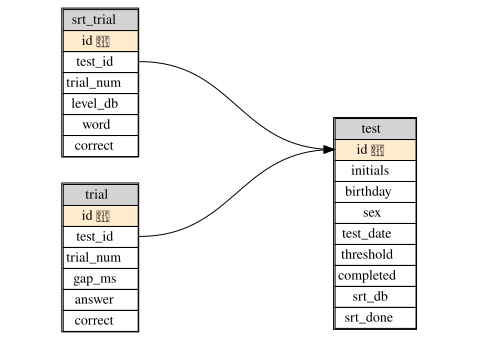

In [ ]:
diagram(db.t['srt_trial', 'test', 'trial'])

## Test logic

In [ ]:
def sort_th(col, sort, dir):
    new_dir = 'desc' if col==sort and dir=='asc' else 'asc'
    mark = (' ↑' if dir=='asc' else ' ↓') if col==sort else ''
    return Th(A(hx_get=f'/tests?sort={col}&dir={new_dir}', hx_target='#tests-table', hx_swap='outerHTML', hx_push_url='true')(col+mark))

def row_link(tid, v): return Td(A(href=f'/tests/{tid}', cls='block w-full')(v))

@rt('/tests')
def get(sort:str='id', dir:str='desc'):
    cols = tests_db.columns_dict.keys()
    if sort not in cols: sort = 'id'
    tsts = list(map(asdict, tests_db(order_by=f'{sort} {"desc" if dir=="desc" else "asc"}')))
    if not tsts: return Div(cls='flex justify-center pt-8')(
        Card(
            H3('No tests found'),
            P('Create ', A(href='/tests/new', cls=AT.primary)('a new test'), ' to get started.'),
            cls=TextT.center))
    return Table(id='tests-table')(
        Thead(Tr(*[sort_th(col, sort, dir) for col in cols])),
        Tbody(*[Tr(*[row_link(tst['id'], tst[col]) for col in cols]) for tst in tsts]))

In [ ]:
STEP,START_GAP,N_REVERSALS = 0.8,100.0,6

def step_state(gap, streak, last_dir, ok):
    "Advance staircase one trial; returns new gap, streak, direction, and whether it reversed"
    new_dir = None
    if ok:
        streak += 1
        if streak>1: gap,streak,new_dir = gap*STEP,0,'down'
    else: gap,streak,new_dir = gap/STEP,0,'up'
    return gap,streak,(new_dir or last_dir),bool(new_dir and last_dir and new_dir!=last_dir)

def replay(trls):
    "Derive current staircase state from a test's trials"
    gap,streak,last_dir,revs = START_GAP,0,None,[]
    for t in trls:
        gap,streak,last_dir,rev = step_state(gap, streak, last_dir, t.answer==t.correct)
        if rev: revs.append(gap)
    return gap,streak,last_dir,revs

def get_trials(tid): return trials_db(where='test_id=?', where_args=[tid], order_by='trial_num')

In [ ]:
@rt('/tests/new')
def get():
    return Div(cls='pt-4 flex justify-center')(
        Card(
            H3('New test'),
            Form(method='post', action='/tests')(
                LabelInput('Initials', id='initials', name='initials', required=True),
                LabelInput('Birthday', id='birthday', name='birthday', type='date', required=True),
                Fieldset(
                    Legend(cls=TextT.medium)('Sex'),
                    DivHStacked(
                        LabelRadio('Male', id='sex-m', name='sex', value='M'),
                        LabelRadio('Female', id='sex-f', name='sex', value='F'),
                        LabelRadio('Other', id='sex-o', name='sex', value='O'),
                        cls='gap-4 p-4')),
                Button(cls=ButtonT.primary)('Start test')),
            cls='w-96'))

@rt('/tests')
def post(initials:str, birthday:str, sex:str):
    t = tests_db.insert(Test(initials=initials, birthday=birthday, sex=sex, test_date=str(date.today()), threshold=0.0))
    return Redirect(f'/tests/{t.id}')

In [ ]:
def patient_cards(t, **attrs):
    return DivHStacked(
        Card(
            P(f'Initials: {t.initials}'),
            P(f'Birthday: {t.birthday}'),
            P(f'Sex: {t.sex}'),
            cls='w-full'),
        Card(P(f'Threshold: {t.threshold:.1f} ms' if t.completed else 'Threshold: pending'),
            P(f'Test date: {t.test_date}'),
            P(f'Status: {'Completed' if t.completed else 'In progress'}'),
            cls='w-full'),
        cls='items-stretch gap-4', id='patient-card', **attrs)

def gap_chart(trl):
    return ApexChart(
        opts={
            'chart': {'type':'line', 'zoom':{'enabled':False}, 'toolbar':{'show':False}, 'height':380},
            'series': [{'name':'Gap (ms)', 'data':[t.gap_ms for t in trl]}],
            'xaxis': {'title':{'text':'Trial number'}, 'categories':[t.trial_num for t in trl]},
            'yaxis': {'title':{'text':'Gap (ms)'}, 'decimalsInFloat':0}},
        cls='w-full')

def done_card(t, n):
    return Card(
        H4('Test complete'),
        P(f'Trials: {n}'),
        P(cls=TextPresets.bold_lg)(f'Threshold: {t.threshold:.0f} ms'),
        A(href='/tests/new', cls=AT.primary)('New test'))

In [ ]:
def test_panel(tid):
    t = tests_db[tid]
    trl = get_trials(tid)
    gap,_,_,revs = replay(trl)
    panel = done_card(t, len(trl)) if t.completed else trial_card(tid, len(trl)+1, gap, revs, random.choice(['left','right']), toj_gain(t.srt_db))
    return Div(id='test-panel', cls='flex flex-col gap-4')(panel, gap_chart(trl))

@rt('/tests/{tid}')
def get(tid:int):
    t = tests_db[tid]
    hdr = (Script(src='/js/playStimulus.js'), patient_cards(t))
    if not t.srt_done: return Container(*hdr, srt_panel(tid), cls='flex flex-col gap-4 p-8')
    if not srt_ok(t.srt_db): return Container(*hdr, headroom_card(tid, t), cls='flex flex-col gap-4 p-8')
    return Container(*hdr, test_panel(tid), cls='flex flex-col gap-4 p-8')

@rt('/tests/{tid}/trials')
def post(tid:int, answer:str, correct:str):
    t = tests_db[tid]
    if t.completed: return test_panel(tid)
    trl = get_trials(tid)
    gap,streak,last_dir,revs = replay(trl)
    ngap,_,_,rev = step_state(gap, streak, last_dir, answer==correct)
    trials_db.insert(Trial(test_id=tid, trial_num=len(trl)+1, gap_ms=gap, answer=answer, correct=correct))
    if rev: revs.append(ngap)
    if len(revs)>=N_REVERSALS:
        tests_db.update(dict(id=tid, threshold=sum(revs[-4:])/4, completed=True))
        return test_panel(tid), patient_cards(tests_db[tid], hx_swap_oob='true')
    return test_panel(tid)

def trial_card(tid, num, gap, revs, side, lvl):
    return Card(
        H4(f'Trial {num} — gap {gap:.1f} ms — reversals {len(revs)}/{N_REVERSALS}'),
        P('Put on headphones. Click play, then say which ear heard the sound first.'),
        Button(submit=False, onclick=f'playTOJ("{side}", {gap}, {lvl})', cls=ButtonT.secondary)('Play sound'),
        Form(hx_post=f'/tests/{tid}/trials', hx_target='#test-panel')(
            Input(type='hidden', name='correct', value=side),
            DivHStacked(
                LabelRadio('Left', id='answer-left', name='answer', value='left', required=True, container=None),
                LabelRadio('Right', id='answer-right', name='answer', value='right', required=True, container=None),
                Button(id='answer-next', cls=ButtonT.primary)('Next trial'))),
        Style('input[type=radio]:checked ~ #answer-next {visibility:visible} #answer-next {visibility:hidden}'))

## Calibration logic

In [ ]:
def srt_panel(tid):
    t = tests_db[tid]
    trl = get_srt_trials(tid)
    lvl,_,revs = srt_replay(trl)
    return Div(id='srt-panel', cls='flex flex-col gap-4')(
        srt_card(tid, len(trl)+1, lvl, next_word(trl), revs),
        srt_chart(trl))

def srt_chart(trl):
    return ApexChart(opts=dict(
            chart=dict(type='line', zoom=dict(enabled=False), toolbar=dict(show=False), height=380),
            series=[dict(name='Level (dB)', data=[t.level_db for t in trl])],
            xaxis=dict(title=dict(text='Trial number'), categories=[t.trial_num for t in trl]),
            yaxis=dict(title=dict(text='Level (dB)'), decimalsInFloat=0)),
        cls='w-full')

def srt_card(tid, num, lvl, word, revs):
    return Card(
        H4(f'Calibration trial {num} — {lvl:.0f} dB — reversals {len(revs)}/{SRT_REVERSALS}'),
        P('Play the word, then mark whether the patient repeated it correctly.'),
        P(cls='text-3xl font-bold tracking-wide py-2')(word),
        Button(type='button', onclick=f'playSpondee("{word}", {lvl})', cls=ButtonT.secondary)('Play word'),
        Form(hx_post=f'/tests/{tid}/srt', hx_target='#srt-panel', hx_swap='outerHTML')(
            Input(type='hidden', name='word', value=word),
            Input(type='hidden', name='level_db', value=str(lvl)),
            DivHStacked(
                Button(name='correct', value='1', cls=ButtonT.primary)('Correct'),
                Button(name='correct', value='0', cls=ButtonT.secondary)('Incorrect'),
                cls='gap-4 pt-4')))

def headroom_card(tid, t):
    return Card(
        H4(cls=TextT.error+TextT.bold)('Insufficient headroom'),
        P(f'SRT came out at {t.srt_db:.1f} dB, so the TOJ level would be {toj_gain(t.srt_db):.1f} dB — above full scale.'),
        P('Set the tablet volume to maximum and recalibrate.'),
        Form(method='post', action=f'/tests/{tid}/recalibrate')(Button(cls=ButtonT.primary)('Recalibrate')))

In [ ]:
@rt('/tests/{tid}/srt')
def post(tid:int, word:str, level_db:float, correct:int):
    t = tests_db[tid]
    if t.srt_done: return
    trl = get_srt_trials(tid)
    lvl,last_dir,revs = srt_replay(trl)
    nlvl,ndir,rev = srt_step(lvl, last_dir, len(revs), bool(correct))
    srt_trials_db.insert(SrtTrial(test_id=tid, trial_num=len(trl)+1, level_db=level_db, word=word, correct=bool(correct)))
    if rev: revs.append(nlvl)
    if len(revs)>=SRT_REVERSALS:
        tests_db.update(dict(id=tid, srt_db=sum(revs[-4:])/4, srt_done=True))
        t = tests_db[tid]
        panel = headroom_card(tid, t) if not srt_ok(t.srt_db) else test_panel(tid)
        return Div(id='srt-panel')(panel), patient_cards(t, hx_swap_oob='true')
    return srt_panel(tid)

@rt('/tests/{tid}/recalibrate')
def post(tid:int):
    srt_trials_db.delete_where('test_id=?', [tid])
    tests_db.update(dict(id=tid, srt_db=0.0, srt_done=False))
    return Redirect(f'/tests/{tid}')

In [ ]:
SRT_START,SRT_BIG,SRT_SMALL,SRT_REVERSALS,SRT_HEADROOM = -30.0,5.0,2.0,6,50.0
SPONDEES = ('abelha boneca cadeira').split()

def srt_step(lvl, last_dir, nrev, ok):
    "Advance SRT staircase one trial; returns new level, direction, and whether it reversed"
    step = SRT_BIG if nrev<1 else SRT_SMALL
    new_dir = 'down' if ok else 'up'
    return (lvl-step if ok else lvl+step),new_dir,bool(last_dir and new_dir!=last_dir)

def srt_replay(trl):
    "Derive current SRT staircase state from a test's trials"
    lvl,last_dir,revs = SRT_START,None,[]
    for t in trl:
        lvl,last_dir,rev = srt_step(lvl, last_dir, len(revs), t.correct)
        if rev: revs.append(lvl)
    return lvl,last_dir,revs

def get_srt_trials(tid): return srt_trials_db(where='test_id=?', where_args=[tid], order_by='trial_num')
def next_word(trl): return random.choice([w for w in SPONDEES if w not in {t.word for t in trl}] or SPONDEES)
def toj_gain(srt_db): return srt_db + SRT_HEADROOM
def srt_ok(srt_db): return srt_db <= -SRT_HEADROOM

In [ ]:
serve()

How do we make this trial_card work? That is, the form sends the data to the server and then just replaces itself in the current page without a full refresh?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Use HTMX to target the card and replace the card element itself. The important changes are:

1. Add `hx_swap='outerHTML'` to the form.
2. Return a new `trial_card(...)` from the POST handler instead of redirecting.

```python
def trial_card(tid, num, gap, revs, side, lvl):
    return Card(
        H4(f'Trial {num} — gap {gap:.1f} ms — reversals {len(revs)}/{N_REVERSALS}'),
        P('Put on headphones. Click play, then say which ear heard the sound first.'),
        Button('Play sound', type='button', onclick=f'playTOJ("{side}", {gap}, {lvl})', cls=ButtonT.secondary),
        Form(hx_post=f'/tests/{tid}/trials', hx_target='#trial-card', hx_swap='outerHTML')(
            Input(type='hidden', name='correct', value=side),
            DivHStacked(
                LabelRadio('Left', id='answer-left', name='answer', value='left', required=True, container=None),
                LabelRadio('Right', id='answer-right', name='answer', value='right', required=True, container=None),
                Button('Next trial', id='answer-next', cls=ButtonT.primary))),
        Style('input[type=radio]:checked ~ #answer-next {visibility:visible} #answer-next {visibility:hidden}'),
        id='trial-card')
```

Then return the next card from the POST route:

```python
@rt('/tests/{tid}/trials')
def post(tid:int, answer:str, correct:str):
    t = tests[tid]
    trl = get_trials(tid)
    gap,streak,last_dir,revs = replay(trl)
    ngap,nstreak,ndir,rev = step_state(gap, streak, last_dir, answer==correct)
    trials.insert(Trial(test_id=tid, trial_num=len(trl)+1, gap_ms=gap, answer=answer, correct=correct))
    if rev: revs.append(ngap)
    if len(revs)>=N_REVERSALS:
        tests.update(dict(id=tid, threshold=sum(revs[-4:])/4, completed=True))
        return done_card(t, len(trl)+1)
    ntrl = get_trials(tid)
    ngap,_,_,nrevs = replay(ntrl)
    return trial_card(tid, len(ntrl)+1, ngap, nrevs, random.choice(['left','right']), toj_gain(t.srt_db))
```

`hx_target='#trial-card'` selects the existing card, and `hx_swap='outerHTML'` replaces that entire element with the returned HTML. No full-page redirect is needed.

Why did the POST logic change so drastically?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

It shouldn’t have changed so drastically. The existing POST logic already records the answer and advances the staircase correctly. Only its response behavior needed to change.

The minimal adjustment is:

- Keep the existing calculations and database writes.
- Replace the final redirect with the HTML fragment that should replace `#trial-card`.
- Return `done_card(...)` when the test completes; otherwise return the next `trial_card(...)`.

```python
@rt('/tests/{tid}/trials')
def post(tid:int, answer:str, correct:str):
    t = tests[tid]
    if t.completed: return Redirect(f'/tests/{tid}')
    trl = get_trials(tid)
    gap,streak,last_dir,revs = replay(trl)
    ngap,nstreak,ndir,rev = step_state(gap, streak, last_dir, answer==correct)
    trials.insert(Trial(test_id=tid, trial_num=len(trl)+1, gap_ms=gap, answer=answer, correct=correct))
    if rev: revs.append(ngap)
    if len(revs)>=N_REVERSALS:
        tests.update(dict(id=tid, threshold=sum(revs[-4:])/4, completed=True))
        return done_card(tests[tid], len(trl)+1)
    return trial_card(tid, len(trl)+2, ngap, revs, random.choice(['left','right']), toj_gain(t.srt_db))
```

The key detail is that the inserted trial is number `len(trl)+1`, so the next trial is `len(trl)+2`. The rest of the original logic remains intact.

Is there not a better pattern here? We have a perfectly good 'tests/{tid}' route that gives everything we need to show for the next trial, why reinvent the wheel at the POST handler? IDK if we can fragment swap redirect in HTMX or change something about our current desing to allow for this?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes — the better pattern is to stop thinking in terms of "the POST returns a card" and instead extract the *renderable region* into a function that both routes call. The duplication exists only because the region is built inline in the GET route.

Factor out the swappable region:

```python
def test_panel(tid):
    t = tests[tid]
    trl = get_trials(tid)
    gap,_,_,revs = replay(trl)
    panel = done_card(t, len(trl)) if t.completed else trial_card(tid, len(trl)+1, gap, revs, random.choice(['left','right']), toj_gain(t.srt_db))
    return Div(panel, gap_chart(trl), id='test-panel', cls='flex flex-col gap-4')
```

The form now targets that region rather than itself, so the chart updates too:

```python
Form(hx_post=f'/tests/{tid}/trials', hx_target='#test-panel', hx_swap='outerHTML')(...)
```

And the POST goes back to being purely about state change, ending with the same render call the GET uses:

```python
@rt('/tests/{tid}/trials')
def post(tid:int, answer:str, correct:str):
    t = tests[tid]
    if t.completed: return test_panel(tid)
    trl = get_trials(tid)
    gap,streak,last_dir,revs = replay(trl)
    ngap,_,_,rev = step_state(gap, streak, last_dir, answer==correct)
    trials.insert(Trial(test_id=tid, trial_num=len(trl)+1, gap_ms=gap, answer=answer, correct=correct))
    if rev: revs.append(ngap)
    if len(revs)>=N_REVERSALS: tests.update(dict(id=tid, threshold=sum(revs[-4:])/4, completed=True))
    return test_panel(tid)
```

Note that `test_panel` re-derives everything from the database, exactly as a page load would, so there is no "next trial number" arithmetic to get wrong and no second copy of the done/in-progress decision.

On your HTMX question: you *can* keep the `Redirect` if you prefer. HTMX follows the 302 transparently, so the response body is the full `/tests/{tid}` page; adding `hx_select='#test-panel'` tells HTMX to pull just that element out of it before swapping:

```python
Form(hx_post=f'/tests/{tid}/trials', hx_target='#test-panel', hx_swap='outerHTML', hx_select='#test-panel')(...)
```

That also achieves zero duplication, at the cost of rendering the whole page server-side and discarding most of it each trial. The factored-function version is cheaper and makes the shared piece explicit, so I'd lean that way.

Two things to watch when you try it: the `Script` for `playStimulus.js` should stay in the page header, outside `#test-panel`, so it is not re-fetched on each swap; and `ApexChart` injects an init script, so confirm the chart actually redraws after the swap rather than coming back blank.

Why am I getting a duplicate chart on fragment swap but no full refresh? I've tried both outerHTML and innerHTML swaps.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Because the swap mode isn't the problem — the *target* is. Your form still says:

```python
Form(hx_post=f'/tests/{tid}/trials', hx_target='#trial-card')(...)
```

but the POST now returns the whole `#test-panel` (card **plus** chart). So whichever swap mode you pick, you end up with two charts:

- `innerHTML`: the returned `#test-panel` div is placed *inside* the old `#trial-card`, which itself sits inside the original `#test-panel`. The original chart is still a sibling of the card, and the response brought a second one. Nested duplicate.
- `outerHTML`: `#trial-card` is replaced by the returned `#test-panel`, but the original chart is a *sibling* of `#trial-card` inside the outer `#test-panel`, so it was never in the replaced region. It survives alongside the new one.

Either way you also now have two elements with `id="test-panel"` in the document, which will make subsequent swaps behave unpredictably since HTMX resolves `#test-panel` to the first match.

The rule is that the target must be the same element the response represents. Since the response is `#test-panel`, target that:

```python
Form(hx_post=f'/tests/{tid}/trials', hx_target='#test-panel', hx_swap='outerHTML')(...)
```

`outerHTML` is required here rather than `innerHTML`, because the returned fragment *includes* the `#test-panel` wrapper itself — `innerHTML` would nest a second `#test-panel` inside the first.

As for no full refresh: that's expected and correct. HTMX only ever replaces the targeted region; there's no page reload in any of these cases, which is why the stale chart just sat there instead of being cleared.

Great! That fixed it. How do I make it so that the patient card is updated out-of-band when the test finishes? Right now, the threshold and status stay stale until a full refresh.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

- ⏳ `web_search(type="search", queries="['site:fastht.ml/docs hx-swap-oob FastHT…", query="site:fastht.ml/docs hx-swap-oob FastHTML")` ⏳


```json {.tool}
{
  "id": "ws_0a43e5f9de691487006acb996608b487d190332642577f57b4",
  "name": "web_search",
  "args": {
    "type": "search",
    "queries": [
      "site:fastht.ml/docs hx-swap-oob FastHTML",
      "site:htmx.org attributes hx-swap-oob"
    ],
    "query": "site:fastht.ml/docs hx-swap-oob FastHTML"
  },
  "result": "Server tool call executed.",
  "server": true
}
```

Give the patient card a stable `id`, then return an out-of-band replacement alongside the normal `#test-panel` response.

```python
def patient_cards(t, **attrs):
    return DivHStacked(
        Card(P(f'Initials: {t.initials}'), P(f'Birthday: {t.birthday}'), P(f'Sex: {t.sex}'), cls='w-full'),
        Card(P(f'Threshold: {t.threshold:.1f} ms' if t.completed else 'Threshold: pending'),
             P(f'Test date: {t.test_date}'), P(f'Status: {'Completed' if t.completed else 'In progress'}'), cls='w-full'),
        cls='items-stretch gap-4', id='patient-card', **attrs)
```

The existing page now renders:

```python
hdr = (Script(src='/js/playStimulus.js'), patient_cards(t))
```

When the test finishes, return the updated panel plus a second element with the same ID and `hx_swap_oob='true'`:

```python
@rt('/tests/{tid}/trials')
def post(tid:int, answer:str, correct:str):
    t = tests[tid]
    if t.completed: return test_panel(tid)
    trl = get_trials(tid)
    gap,streak,last_dir,revs = replay(trl)
    ngap,_,_,rev = step_state(gap, streak, last_dir, answer==correct)
    trials.insert(Trial(test_id=tid, trial_num=len(trl)+1, gap_ms=gap, answer=answer, correct=correct))
    if rev: revs.append(ngap)
    if len(revs)>=N_REVERSALS:
        tests.update(dict(id=tid, threshold=sum(revs[-4:])/4, completed=True))
        return test_panel(tid), patient_cards(tests[tid], hx_swap_oob='true')
    return test_panel(tid)
```

The form still targets the panel:

```python
Form(hx_post=f'/tests/{tid}/trials', hx_target='#test-panel', hx_swap='outerHTML')(...)
```

HTMX replaces `#test-panel` normally, then sees the second `#patient-card` in the response and replaces the existing patient card independently. The response must use `outerHTML` for the panel because `test_panel()` returns the wrapper itself; `hx_swap_oob='true'` defaults to replacing the matching patient-card element. ([fastht.ml](https://www.fastht.ml/docs/tutorials/by_example.html?utm_source=openai))[*](https://www.fastht.ml/docs/tutorials/by_example.html?utm_source=openai "FastHTML By Example – fasthtml")

Now if I do a full load of `/tests/{tid}`, I get duplicate patient cards because I assume that it doesn't activate HTMX and consequently the OOB swap. The cop out would be to refresh all elements on every trial, but I'd like to keep the test efficient, only replacing elements that need to change. Suggestions on how to fix this?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

The duplicate comes from rendering `patient_cards` in two places:

- The full page renders it in `hdr`.
- `test_panel(tid)` also renders it when the test is complete.
- The POST response adds another out-of-band copy.

`hx_swap_oob` is only acted on when HTMX processes an AJAX response. During a normal full-page load, it is just an attribute, so the element renders normally.

Keep `patient_cards` out of `test_panel`. It belongs to the page shell and should be rendered once on a full load:

```python
def test_panel(tid):
    t = tests[tid]
    trl = get_trials(tid)
    gap,_,_,revs = replay(trl)
    panel = done_card(t, len(trl)) if t.completed else trial_card(tid, len(trl)+1, gap, revs, random.choice(['left','right']), toj_gain(t.srt_db))
    return Div(panel, gap_chart(trl), id='test-panel', cls='flex flex-col gap-4')
```

Then the page route remains responsible for the one normal patient card:

```python
@rt('/tests/{tid}')
def get(tid:int):
    t = tests[tid]
    hdr = (Script(src='/js/playStimulus.js'), patient_cards(t))
    if not t.srt_done:
        ...
    if not srt_ok(t.srt_db): ...
    return Container(*hdr, test_panel(tid), cls='flex flex-col gap-4 p-8')
```

Only the completion response includes the out-of-band copy:

```python
@rt('/tests/{tid}/trials')
def post(tid:int, answer:str, correct:str):
    t = tests[tid]
    if t.completed: return test_panel(tid)
    trl = get_trials(tid)
    gap,streak,last_dir,revs = replay(trl)
    ngap,_,_,rev = step_state(gap, streak, last_dir, answer==correct)
    trials.insert(Trial(test_id=tid, trial_num=len(trl)+1, gap_ms=gap, answer=answer, correct=correct))
    if rev: revs.append(ngap)
    if len(revs)>=N_REVERSALS:
        tests.update(dict(id=tid, threshold=sum(revs[-4:])/4, completed=True))
        return test_panel(tid), patient_cards(tests[tid], hx_swap_oob='true')
    return test_panel(tid)
```

The resulting structure is:

- **Full GET**: one ordinary `#patient-card` plus one `#test-panel`.
- **Normal trial POST**: replacement `#test-panel` only.
- **Final trial POST**: replacement `#test-panel` plus an OOB replacement for `#patient-card`.

That preserves the efficient fragment update without making the full page depend on HTMX behavior.

Please explain to me how SRT threshold finding would work in my app. I've seen it done with spondee words and iterative testing. What do I need to implement it?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

SRT (speech reception threshold) is the lowest level at which a listener correctly repeats 50% of spondee words. Spondees — two-syllable words with equal stress on both syllables, like *baseball*, *hotdog*, *railroad* — are used precisely because they're highly redundant and homogeneous in audibility, so the psychometric function is steep. That steepness is what makes a handful of trials enough to pin down a threshold.

**How it differs from your TOJ task**

Your current task is a 2AFC: the correct answer is known to the server, the participant picks left or right, and chance performance is 50%. SRT is an open-set repetition task. The participant says the word out loud, and the *examiner* scores it. There's no meaningful chance level, so the target is the 50% point directly.

This matters for your staircase. Your `step_state` is 2-down/1-up (`streak>=2` before descending), which converges on ~70.7% correct — the right target for a 2AFC gap task. For SRT you want 1-down/1-up, which converges on 50%. Same machinery, different rule.

The other change is the step arithmetic. Your gap staircase is multiplicative (`gap*STEP`), because milliseconds are a ratio scale. Decibels are already logarithmic, so SRT steps are additive: typically 5 dB until the first reversal, then 2 dB for the remainder. And the direction mapping is pleasantly direct — correct means make it harder means *quieter*, so "down" in difficulty is also down in dB.

**What you'd need to add**

1. **A word corpus with audio.** The CID W-1 list is the classic set (36 spondees). You need recordings, and you need to sample without replacement within a run so no word repeats.

2. **Calibration.** This is the genuinely hard part, and it's not a software problem. A browser has no idea what SPL its output produces — that depends on the headphones, the sound card, and the OS volume slider. To report dB HL rather than "dB relative to full scale", you need a per-setup offset constant, measured once with a reference tone and a sound level meter on an artificial ear. Store it per device, then `level_hl = cal_offset + 20*log10(gain)`. Without this, your numbers are internally consistent but not clinically interpretable, and you should label them as such.

3. **Ear selection.** SRT is measured per ear (and sometimes binaurally), so a test needs an `ear` field and separate staircases per ear.

4. **A familiarization phase.** Standard protocol plays the whole word list at a clearly audible level first. Open-set tasks are heavily influenced by whether the listener knows the candidate vocabulary, and familiarization removes that variance.

5. **Examiner scoring UI.** The word is shown to the examiner, not the participant; the examiner marks correct/incorrect.

**What you'd reuse**

Almost all of your architecture. The `replay()` pattern — deriving staircase state by folding over stored trials rather than holding session state — works identically here, and it's the right design. `trials` needs `level_db` instead of (or alongside) `gap_ms`, and a boolean `correct` scored by the examiner rather than a string compared against the stimulus side. Your reversal counting and "mean of the last 4 reversals" threshold calculation carry over unchanged.

**One design fork worth deciding before you write anything**

You could run this closed-set instead: show the participant a grid of the 36 spondees and have them click the one they heard. That breaks from clinical protocol — closed-set SRT runs a few dB better than open-set, so your thresholds won't be comparable to audiometric norms — but it makes the test self-administered and auto-scored, which fits your existing architecture exactly as it stands. Open-set needs a human in the room.

Which way do you want to go? And is this a second test type in the same `test` table with a discriminator column, or a separate table?

The goal of this SRT calibration phase is not to have a clinically relevant result, but instead to set the volume of the audio being played to 50 dB above the SRT. This task will be conducted on a tablet using standard headphones so we couldn't even get an actual decibel reading. Does it make sense?

Also the whole test is performed by the examiner, not the patient.

I'm wondering if we should have a separate database for this calibration process.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes, it makes complete sense, and it's the right move. What you're describing is **dB SL** — sensation level, referenced to the individual listener's own threshold rather than to an absolute SPL. The whole calibration chain you'd otherwise need (sound level meter, artificial ear, per-device offset) exists only to anchor dB HL to a physical reference. If your target is "50 dB above *this person's* SRT on *this* setup", the anchor is the person, and the absolute scale cancels out of the arithmetic entirely.

What still has to be accurate is **relative** attenuation, and that part a browser does exactly right. A Web Audio `GainNode` applied to a normalized buffer is mathematically exact in float32, so a 2 dB step really is 2 dB. Nothing about the tablet's unknown absolute output affects that.

**The one real constraint: headroom**

Work in dBFS, where 0 is digital full scale and everything is negative. You find SRT at some gain `g_srt`, then play TOJ stimuli at `g_srt + 50`. That number must stay ≤ 0, or you clip.

So the hidden requirement is that SRT must land at −50 dBFS or lower. Whether it does depends entirely on where the tablet's volume slider sits. At full volume, speech at 0 dBFS through typical headphones is around 100 dB SPL, so a normal-hearing SRT lands near −80 dBFS — plenty of room. At half volume you might find SRT at −45 dBFS, and SRT+50 is then physically unreachable.

Two consequences for your implementation:

- Set device volume to maximum before calibration and don't touch it again. If it moves between phases, the calibration is void. Worth a checklist screen the examiner confirms.
- Have the app refuse to proceed if `g_srt > -50`. That's a cheap guard that catches the volume-slider failure mode automatically.

```python
SRT_HEADROOM = 50.0
def toj_gain(srt_db): return srt_db + SRT_HEADROOM
def srt_ok(srt_db): return srt_db <= -SRT_HEADROOM
```

**Staircase differences**

Open-set SRT has no chance level, so you want 1-down/1-up converging on 50%, not your 2-down/1-up at 70.7%. And since dB is already logarithmic, steps are additive rather than multiplicative. Standard practice is 5 dB until the first reversal, then 2 dB.

```python
SRT_START,SRT_BIG,SRT_SMALL,SRT_REVERSALS = -70.0,5.0,2.0,6

def srt_step(lvl, last_dir, ok, nrev):
    step = SRT_BIG if nrev<1 else SRT_SMALL
    new_dir = 'down' if ok else 'up'
    return lvl-step if ok else lvl+step, new_dir, bool(last_dir and new_dir!=last_dir)
```

Note that "correct → go down" is both easier to read and correct here: correct means make it harder means quieter.

Since the examiner runs everything, open-set repetition scoring is free — the examiner sees the word, hears the response, clicks correct or incorrect. No need for the closed-set grid I mentioned before.

**On the database question**

Keep it in `cobalt.db`. A separate file buys you nothing and costs real things: no foreign key from calibration to test, no single-transaction writes, manual joins in Python, two files to back up and keep in sync. A calibration isn't an independent entity — it's a phase of one test session, and it should be reachable by FK from the test it calibrates.

What I *would* separate is the **table**. SRT trials and TOJ trials have different units, different scoring, and different staircase rules. Folding them into one `trial` table means nullable `gap_ms`/`level_db` columns and a `phase` discriminator threaded through every query and through `replay()`. Two clean tables is simpler:

```python
class Test: id:int; initials:str; birthday:str; sex:str; test_date:str; srt_db:float; srt_done:bool=False; threshold:float=0.0; completed:bool=False
class SrtTrial: id:int; test_id:int; trial_num:int; level_db:float; word:str; correct:bool

srt_trials = db.create(SrtTrial, pk='id', foreign_keys=[('test_id', 'test', 'id')])
```

`srt_db` and `srt_done` on the test record are the handoff: the TOJ phase reads `srt_db`, and `/tests/{tid}` routes to the calibration panel or the trial panel depending on `srt_done`.

Your `replay()` pattern generalises to this unchanged — fold over `srt_trials` to derive current level, direction, and reversals. Deriving state from stored trials rather than holding it in the session is the thing that makes a two-phase test easy to resume, and it's already how your code works.

One thing still needed regardless: spondee recordings, and sampling without replacement within a run so no word repeats during a staircase.

In [ ]:
!cat js/playStimulus.js

let audioCtx = null;
let audioBuffer = null;
const spondeeBuffers = new Map();
const otherEar = ear => ear === "left" ? "right" : "left";
const dbToGain = db => Math.pow(10, db / 20);

async function loadBuffer(url) {
    audioCtx ??= new AudioContext();
    const response = await fetch(url);
    const arrayBuffer = await response.arrayBuffer();
    return await audioCtx.decodeAudioData(arrayBuffer);
}

async function loadStimulus() { audioBuffer ??= await loadBuffer('/stimulus.wav'); }

async function loadSpondee(word) {
    if (!spondeeBuffers.has(word)) spondeeBuffers.set(word, await loadBuffer(`/spondees/${word}.wav`));
    return spondeeBuffers.get(word);
}

function playBuffer(buffer, startTime, levelDb, pan=null) {
    const source = audioCtx.createBufferSource();
    const gain = audioCtx.createGain();
    source.buffer = buffer;
    gain.gain.value = dbToGain(levelDb);
    let node = source.connect(gain);
    if (pan !== null) {
            const panner = audioCtx.createStereo

Here's the playStimulus.js code showing how to access an audio route. If you need to use javascript, you also have a template to follow.

Can you implement this calibration phase end-to-end now? Assume the recordings are available in .wav format so I can record and place them later.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Here's the full implementation. Five pieces: schema, staircase, UI, routes, JS.

**1. Schema** — replace your `Test`/`Trial` cell:

```python
db = database('cobalt.db')
# dev only
db['trial'].drop(ignore=True)
db['test'].drop(ignore=True)
db['srttrial'].drop(ignore=True)

class Test: id:int; initials:str; birthday:str; sex:str; test_date:str; threshold:float; completed:bool=False; srt_db:float=0.0; srt_done:bool=False
class Trial: id:int; test_id:int; trial_num:int; gap_ms:float; answer:str; correct:str
class SrtTrial: id:int; test_id:int; trial_num:int; level_db:float; word:str; correct:bool
tests = db.create(Test, pk='id')
trials = db.create(Trial, pk='id', foreign_keys=[('test_id', 'test', 'id')])
srt_trials = db.create(SrtTrial, pk='id', foreign_keys=[('test_id', 'test', 'id')])
```

**2. Staircase and word pool** — new cell:

```python
SRT_START,SRT_BIG,SRT_SMALL,SRT_REVERSALS,SRT_HEADROOM = -30.0,5.0,2.0,6,50.0
SPONDEES = ('greyhound schoolboy inkwell whitewash pancake mousetrap eardrum headlight birthday duckpond sidewalk hotdog padlock mushroom hardware workshop '
            'horseshoe armchair baseball stairway cowboy iceberg northwest railroad playground airplane woodwork oatmeal toothbrush farewell grandson '
            'drawbridge doormat hothouse daybreak sunset').split()

def srt_step(lvl, last_dir, nrev, ok):
    "Advance SRT staircase one trial; returns new level, direction, and whether it reversed"
    step = SRT_BIG if nrev<1 else SRT_SMALL
    new_dir = 'down' if ok else 'up'
    return (lvl-step if ok else lvl+step),new_dir,bool(last_dir and new_dir!=last_dir)

def srt_replay(trl):
    "Derive current SRT staircase state from a test's trials"
    lvl,last_dir,revs = SRT_START,None,[]
    for t in trl:
        lvl,last_dir,rev = srt_step(lvl, last_dir, len(revs), t.correct)
        if rev: revs.append(lvl)
    return lvl,last_dir,revs

def get_srt_trials(tid): return srt_trials(where='test_id=?', where_args=[tid], order_by='trial_num')
def next_word(trl): return random.choice([w for w in SPONDEES if w not in {t.word for t in trl}] or SPONDEES)
def toj_gain(srt_db): return srt_db + SRT_HEADROOM
def srt_ok(srt_db): return srt_db <= -SRT_HEADROOM
```

**3. UI** — new cell:

```python
def srt_chart(trl):
    return ApexChart(opts={
        'chart': {'type':'line', 'zoom':{'enabled':False}, 'toolbar':{'show':False}, 'height':380},
        'series': [{'name':'Level (dB)', 'data':[t.level_db for t in trl]}],
        'xaxis': {'title':{'text':'Trial number'}, 'categories':[t.trial_num for t in trl]},
        'yaxis': {'title':{'text':'Level (dB)'}, 'decimalsInFloat':0}},
        cls='w-full')

def srt_card(tid, num, lvl, word, revs):
    return Card(
        H4(f'Calibration trial {num} — {lvl:.0f} dB — reversals {len(revs)}/{SRT_REVERSALS}'),
        P('Play the word, then mark whether the patient repeated it correctly.'),
        P(word, cls='text-3xl font-bold tracking-wide py-2'),
        Button('Play word', type='button', onclick=f'playSpondee("{word}", {lvl})', cls=ButtonT.secondary),
        Form(method='post', action=f'/tests/{tid}/srt')(
            Input(type='hidden', name='word', value=word),
            Input(type='hidden', name='level_db', value=str(lvl)),
            DivHStacked(
                Button('Correct', name='correct', value='1', cls=ButtonT.primary),
                Button('Incorrect', name='correct', value='0', cls=ButtonT.secondary),
                cls='gap-4 pt-4')))

def headroom_card(tid, t):
    return Card(
        H4('Insufficient headroom', cls='text-red-500'),
        P(f'SRT came out at {t.srt_db:.1f} dB, so the TOJ level would be {toj_gain(t.srt_db):.1f} dB — above full scale.'),
        P('Set the tablet volume to maximum and recalibrate.'),
        Form(method='post', action=f'/tests/{tid}/recalibrate')(Button('Recalibrate', cls=ButtonT.primary)))
```

**4. Routes** — replace your `/tests/{tid}` GET and add two:

```python
@rt('/tests/{tid}')
def get(tid:int):
    t = tests[tid]
    hdr = (Script(src='/js/playStimulus.js'), patient_cards(t))
    if not t.srt_done:
        trl = get_srt_trials(tid)
        lvl,_,revs = srt_replay(trl)
        return Container(*hdr, srt_card(tid, len(trl)+1, lvl, next_word(trl), revs), srt_chart(trl), cls='flex flex-col gap-4 p-8')
    if not srt_ok(t.srt_db): return Container(*hdr, headroom_card(tid, t), cls='flex flex-col gap-4 p-8')
    trl = get_trials(tid)
    gap,_,_,revs = replay(trl)
    panel = done_card(t, len(trl)) if t.completed else trial_card(tid, len(trl)+1, gap, revs, random.choice(['left','right']), toj_gain(t.srt_db))
    return Container(*hdr, panel, gap_chart(trl), cls='flex flex-col gap-4 p-8')

@rt('/tests/{tid}/srt')
def post(tid:int, word:str, level_db:float, correct:int):
    t = tests[tid]
    if t.srt_done: return Redirect(f'/tests/{tid}')
    trl = get_srt_trials(tid)
    lvl,last_dir,revs = srt_replay(trl)
    nlvl,ndir,rev = srt_step(lvl, last_dir, len(revs), bool(correct))
    srt_trials.insert(SrtTrial(test_id=tid, trial_num=len(trl)+1, level_db=level_db, word=word, correct=bool(correct)))
    if rev: revs.append(nlvl)
    if len(revs)>=SRT_REVERSALS: tests.update(dict(id=tid, srt_db=sum(revs[-4:])/4, srt_done=True))
    return Redirect(f'/tests/{tid}')

@rt('/tests/{tid}/recalibrate')
def post(tid:int):
    srt_trials.delete_where('test_id=?', [tid])
    tests.update(dict(id=tid, srt_db=0.0, srt_done=False))
    return Redirect(f'/tests/{tid}')
```

`trial_card` needs the extra arg threaded into the onclick:

```python
def trial_card(tid, num, gap, revs, side, lvl):
    return Card(
        H4(f'Trial {num} — gap {gap:.1f} ms — reversals {len(revs)}/{N_REVERSALS}'),
        P('Put on headphones. Click play, then say which ear heard the sound first.'),
        Button('Play sound', type='button', onclick=f'playTOJ("{side}", {gap}, {lvl})', cls=ButtonT.secondary),
        Form(method='post', action=f'/tests/{tid}/trials')(
            Input(type='hidden', name='correct', value=side),
            DivHStacked(
                LabelRadio('Left', id='answer-left', name='answer', value='left', required=True, container=None),
                LabelRadio('Right', id='answer-right', name='answer', value='right', required=True, container=None),
                Button('Next trial', id='answer-next', cls=ButtonT.primary))),
        Style('input[type=radio]:checked ~ #answer-next {visibility:visible} #answer-next {visibility:hidden}'))
```

**5. `js/playStimulus.js`** — rewritten to factor out buffer loading and add a gain stage:

```javascript
let audioCtx = null;
let audioBuffer = null;
const spondeeBuffers = new Map();
const otherEar = ear => ear === "left" ? "right" : "left";
const dbToGain = db => Math.pow(10, db / 20);

async function loadBuffer(url) {
    audioCtx ??= new AudioContext();
    const response = await fetch(url);
    const arrayBuffer = await response.arrayBuffer();
    return await audioCtx.decodeAudioData(arrayBuffer);
}

async function loadStimulus() { audioBuffer ??= await loadBuffer('/stimulus.wav'); }

async function loadSpondee(word) {
    if (!spondeeBuffers.has(word)) spondeeBuffers.set(word, await loadBuffer(`/spondees/${word}.wav`));
    return spondeeBuffers.get(word);
}

function playBuffer(buffer, startTime, levelDb, pan=null) {
    const source = audioCtx.createBufferSource();
    const gain = audioCtx.createGain();
    source.buffer = buffer;
    gain.gain.value = dbToGain(levelDb);
    let node = source.connect(gain);
    if (pan !== null) {
        const panner = audioCtx.createStereoPanner();
        panner.pan.value = pan;
        node = node.connect(panner);
    }
    node.connect(audioCtx.destination);
    source.start(startTime);
}

function playInEar(ear, startTime, levelDb) {
    playBuffer(audioBuffer, startTime, levelDb, ear === "left" ? -1 : 1);
}

function playBeep(startTime, duration, levelDb, freq=440) {
    const osc = audioCtx.createOscillator();
    const gain = audioCtx.createGain();
    osc.frequency.value = freq;
    gain.gain.value = dbToGain(levelDb);
    osc.connect(gain).connect(audioCtx.destination);
    osc.start(startTime);
    osc.stop(startTime + duration);
}

async function playSpondee(word, levelDb) {
    const buffer = await loadSpondee(word);
    await audioCtx.resume();
    playBuffer(buffer, audioCtx.currentTime, levelDb);
}

async function playTOJ(firstEar, gapMs, levelDb, beepDuration=0.5) {
    await loadStimulus();
    await audioCtx.resume();
    const now = audioCtx.currentTime;
    playBeep(now, beepDuration, levelDb);
    playInEar(firstEar, now + beepDuration + 1, levelDb);
    playInEar(otherEar(firstEar), now + beepDuration + 1 + audioBuffer.duration + (gapMs / 1000), levelDb);
}
```

Put recordings at `js/../spondees/{word}.wav` — i.e. a `spondees/` folder beside `js/`, named exactly as in `SPONDEES`.

---

Four things worth knowing about what's above:

**RMS-normalize everything to the same level, spondees and `stimulus.wav` alike.** This is the one prep step that the whole scheme depends on. The "+50 dB" transfer is only meaningful if a given gain value produces the same loudness for the TOJ stimulus as it did for the spondees. Peak normalization isn't enough — words vary a lot in crest factor. Normalize to around −20 dBFS RMS, which leaves peak headroom while keeping the numbers comfortable.

**The reversal-value convention follows your existing TOJ code**, appending the *new* level rather than the one just tested. That's a half-step offset, but down-reversals are biased low by exactly the amount up-reversals are biased high, so over 4 reversals it cancels. Consistent with `replay()`, so leave it or change both together.

**The beep now rides the calibrated gain.** Previously it was fixed at 0.5 amplitude; at a −70 dB stimulus level that would have been roughly 65 dB louder than the thing it's cueing. Tying it to `levelDb` keeps the ratio sane, though a 440 Hz tone will sound somewhat quieter than broadband speech at equal gain. Adjust with a fixed offset if the examiner finds it too subtle.

**`SRT_START = -30.0` is a guess.** It should be comfortably audible so the staircase descends from above — which also gives implicit familiarization with the word set. Run it once on yourself at max tablet volume and adjust: if the first several trials are trivially correct you're starting too high and wasting trials; if trial 1 is already a miss you're starting too low.

How do I do RMS normalisation in Audacity?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Audacity has this built in, though it's slightly buried because the obvious-sounding "Normalize" effect is peak-based, not RMS.

**Single file**

1. Select all (Ctrl+A)
2. **Effect → Volume and Compression → Loudness Normalization**
3. In the *Normalize* dropdown choose **RMS** (default is perceived loudness / LUFS)
4. Set the target to **−20 dB**
5. Uncheck *Normalize stereo channels independently* — you want the ear balance left alone
6. Apply

**Batch across all 36 spondees**

Doing that by hand 36 times is tedious and error-prone, so use a macro:

1. **Tools → Macros → New**, name it e.g. `rms20`
2. **Insert** → add *Loudness Normalization*, click **Edit Parameters**, set RMS / −20 dB
3. **Insert** → add *Export as WAV*
4. Close, then **File → Apply Macro → To Files…** and select all your recordings

Output lands in a `macro-output` folder next to the originals.

**The gotcha that matters here**

RMS is measured over the entire selection, silence included. A recording with two seconds of dead air before the word has a lower RMS than a tightly trimmed one, so normalization will boost it — and it'll come out perceptibly louder than its neighbours. Since your whole calibration rests on every word being equally audible, trim leading and trailing silence to something consistent (~100 ms) *before* normalizing.

**Verify afterwards**

Select a few files and check **Analyze → Contrast** (reports RMS directly), or just eyeball the waveforms — at −20 dBFS RMS, speech peaks should sit around −6 to −3 dBFS with nothing touching the rails.

## Discoveries
- Tailwind's Play CDN is compiled at runtime, so it doesn't always work with HTMX swaps if there's a new class in a fragment.
- FastHTML `Redirect` is a Starlette `RedirectResponse` wrapper that uses 303 by default, not 307; useful for PRG.

Session cookie
- Stored client-side.
- Can be read and modified; signed cookies *do* flag tampering, however.
- Lasts for an entire, well, session.
- Very tiny and JSONy.

Request scope
- Stored server-side.
- Never exposed to the user.
- Lasts for a single HTTP request.
- Stores whatever you want.
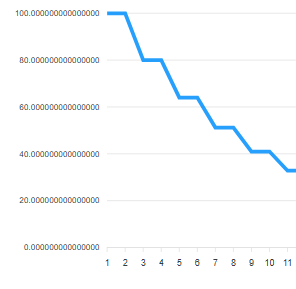